# Q2 · 03 RoBERTa fine-tuning and pooling ablation

**Model.** Pre-trained `roberta-base` → last hidden layer → **masked mean pooling** over every non-padding token → dropout (0.1) → linear (5). The whole encoder is fine-tuned.

$$\text{pooled} = \frac{\sum_t m_t\, h_t}{\sum_t m_t}, \qquad m_t = \text{attention\_mask}_t$$

**Ablation.** The same model with **first-token pooling** (only the `<s>` vector, $h_0$). Everything else, including seeds and data order, is identical, so any gap is down to pooling.

| | |
|---|---|
| Loss | cross-entropy |
| Optimiser | AdamW, lr 2e-5, weight decay 0.01 (none on biases and LayerNorm) |
| Schedule | 6% linear warmup, then linear decay to 0 |
| Precision | fp16 autocast + GradScaler on T4 / P100, bf16 on Ampere |
| Batches | 32 reviews, grouped by length, padded per batch; gradient clipping at 1.0 |
| Epochs | 2, validation twice per epoch, best validation macro-F1 checkpoint kept |
| Seeds | 42 and 43 for each pooling (4 runs) |

The test split is not loaded in this notebook.

In [1]:
import gc
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")
BRANCH = "main"   # the branch to clone when this notebook runs outside the repo (e.g. imported into Kaggle)

root = Path.cwd().resolve()
while not (root / "common").is_dir() and root != root.parent:
    root = root.parent
if not (root / "common").is_dir():
    import subprocess
    root = Path.cwd() / "NLP-Group-Assignment-2"
    if not root.exists():
        subprocess.run(["git", "clone", "-q", "-b", BRANCH,
                        "https://github.com/Akshats-git/NLP-Group-Assignment-2.git", str(root)], check=True)
    os.chdir(root / "Question-2")
sys.path[:0] = [str(root), str(root / "Question-2")]

import torch
from common import DEFAULT_SEEDS, get_device

LIMIT = int(os.environ.get("Q2_LIMIT", 0)) or None   # set for a quick run on a random subset
DEVICE = os.environ.get("Q2_DEVICE", "")             # empty picks cuda, then mps, then cpu
print(get_device(DEVICE or None), torch.cuda.device_count(), "GPU(s)", [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])

cuda 2 GPU(s) ['Tesla T4', 'Tesla T4']


## 1. The model

A forward pass on four real reviews, to check shapes and that both pooling variants are wired up. RoBERTa's padding id is 1 and the attention mask decides what the mean pooling averages over.

In [2]:
from common import count_parameters, format_count
from q2 import roberta_data
from q2.data import load_reviews
from q2.models import RobertaClassifier

tokenizer = roberta_data.get_tokenizer()
sample = roberta_data.tokenize(load_reviews(("validation",), limit=4), tokenizer)["validation"]
batch = next(iter(roberta_data.make_loader(sample, tokenizer, batch_size=4, num_workers=0)))
print({k: tuple(v.shape) for k, v in batch.items()})

for pooling in ("mean", "first"):
    model = RobertaClassifier(pooling=pooling).eval()
    with torch.no_grad():
        logits = model(batch["input_ids"], batch["attention_mask"])
    params = count_parameters(model)
    print(f"{pooling:>5} pooling: logits {tuple(logits.shape)}, {format_count(params['trainable'])} trainable parameters")
del model
_ = gc.collect()

{'input_ids': (4, 256), 'attention_mask': (4, 256), 'labels': (4,)}


[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


 mean pooling: logits (4, 5), 124.06M trainable parameters


[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


first pooling: logits (4, 5), 124.06M trainable parameters


## 2. Training runs

Each run writes `outputs/results/<run>/` (run info, history, summary, validation predictions) and keeps its best weights in `outputs/checkpoints/<run>/best.pt`. A run that already has a `summary.json` is skipped. On Kaggle, attaching an earlier version of this notebook as an input brings its finished runs back first, so a long job can be split over several versions.

In [3]:
from common import load_json, results_dir
from q2.kaggle import import_finished_runs
from q2.train_roberta import RobertaConfig, train

print("imported from earlier versions:", import_finished_runs("roberta_*") or "none")

runs = [RobertaConfig(pooling=pooling, seed=seed, limit=LIMIT, epochs=1 if LIMIT else 2, device=DEVICE)
        for pooling in ("mean", "first") for seed in DEFAULT_SEEDS]

summaries = {}
for config in runs:
    done = results_dir(2) / config.run_name / "summary.json"
    if done.exists():
        print(f"{config.run_name}: already trained, loading its summary")
        summaries[config.run_name] = load_json(done)
        continue
    summaries[config.run_name] = train(config)
    gc.collect()
    torch.cuda.empty_cache()

imported from earlier versions: none


[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


roberta_mean_seed42: 200,000 train reviews, 6,250 batches/epoch, 12,500 optimiser steps, cuda x2, amp torch.float16
  epoch 0.50 | train loss 1.1678 | val loss 1.0189 acc 0.5570 macro-F1 0.5520 MAE 0.5824 | 13.2 min
  epoch 1.00 | train loss 0.9824 | val loss 0.9578 acc 0.5762 macro-F1 0.5690 MAE 0.5414 | 26.4 min
  epoch 1.50 | train loss 0.9248 | val loss 0.9405 acc 0.5838 macro-F1 0.5762 MAE 0.5190 | 39.6 min
  epoch 2.00 | train loss 0.9032 | val loss 0.9174 acc 0.5898 macro-F1 0.5869 MAE 0.4970 | 52.8 min
best: epoch 2.00, val macro-F1 0.5869, total 52.8 min


[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


roberta_mean_seed43: 200,000 train reviews, 6,250 batches/epoch, 12,500 optimiser steps, cuda x2, amp torch.float16
  epoch 0.50 | train loss 1.1621 | val loss 1.0534 acc 0.5466 macro-F1 0.5332 MAE 0.6198 | 13.2 min
  epoch 1.00 | train loss 0.9811 | val loss 0.9370 acc 0.5830 macro-F1 0.5782 MAE 0.5186 | 26.4 min
  epoch 1.50 | train loss 0.9255 | val loss 0.9212 acc 0.5914 macro-F1 0.5829 MAE 0.5046 | 39.7 min
  epoch 2.00 | train loss 0.8956 | val loss 0.9134 acc 0.5940 macro-F1 0.5891 MAE 0.4914 | 52.8 min
best: epoch 2.00, val macro-F1 0.5891, total 52.8 min


...

  epoch 0.50 | train loss 1.1901 | val loss 1.0336 acc 0.5594 macro-F1 0.5527 MAE 0.5916 | 13.2 min
  epoch 1.00 | train loss 1.0019 | val loss 0.9643 acc 0.5832 macro-F1 0.5756 MAE 0.5390 | 26.3 min
  epoch 1.50 | train loss 0.9423 | val loss 0.9492 acc 0.5870 macro-F1 0.5777 MAE 0.5238 | 39.4 min
  epoch 2.00 | train loss 0.9169 | val loss 0.9265 acc 0.5942 macro-F1 0.5894 MAE 0.5026 | 52.5 min
best: epoch 2.00, val macro-F1 0.5894, total 52.5 min


[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


roberta_first_seed43: 200,000 train reviews, 6,250 batches/epoch, 12,500 optimiser steps, cuda x2, amp torch.float16


/kaggle/working/NLP-Group-Assignment-2/Question-2/q2/train_roberta.py:148: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


  epoch 0.50 | train loss 1.1818 | val loss 1.0608 acc 0.5456 macro-F1 0.5337 MAE 0.6290 | 13.1 min
  epoch 1.00 | train loss 0.9959 | val loss 0.9617 acc 0.5786 macro-F1 0.5742 MAE 0.5328 | 26.3 min
  epoch 1.50 | train loss 0.9438 | val loss 0.9441 acc 0.5888 macro-F1 0.5802 MAE 0.5158 | 39.5 min
  epoch 2.00 | train loss 0.9115 | val loss 0.9213 acc 0.5940 macro-F1 0.5895 MAE 0.4990 | 52.6 min
best: epoch 2.00, val macro-F1 0.5895, total 52.6 min


## 3. Validation results and the ablation

Mean ± standard deviation over the two seeds, at each run's best checkpoint. These are validation numbers, used for model selection. The test-set comparison comes in the evaluation step.

In [4]:
from IPython.display import Markdown
from common import History, format_mean_std, markdown_table, save_json
from common.metrics import summarize_runs

METRICS = {"accuracy": "Accuracy (%)", "macro_f1": "Macro-F1 (%)", "mae": "MAE (stars)"}
rows, by_pooling = [], {}
for pooling, label in (("mean", "Mean pooling"), ("first", "First-token pooling")):
    vals = [summaries[c.run_name]["val"] for c in runs if c.pooling == pooling]
    summary = summarize_runs(vals)
    by_pooling[pooling] = summary
    rows.append({"RoBERTa": label,
                 **{name: format_mean_std(summary[k]["values"], scale=1 if k == "mae" else 100, digits=2 if k != "mae" else 3)
                    for k, name in METRICS.items()},
                 "best epoch": ", ".join(str(summaries[c.run_name]["best_epoch"]) for c in runs if c.pooling == pooling)})
if LIMIT is None:
    save_json(by_pooling, results_dir(2) / "roberta_validation_summary.json")
Markdown(markdown_table(rows))

| RoBERTa | Accuracy (%) | Macro-F1 (%) | MAE (stars) | best epoch |
|---|---|---|---|---|
| Mean pooling | 59.19 ± 0.30 | 58.80 ± 0.16 | 0.494 ± 0.004 | 2.0, 2.0 |
| First-token pooling | 59.41 ± 0.01 | 58.94 ± 0.01 | 0.501 ± 0.003 | 2.0, 2.0 |

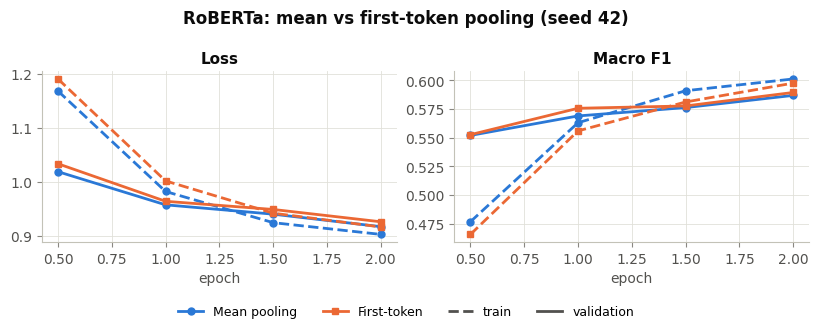

In [5]:
from common import figures_dir
from common.plotting import plot_history

seed = DEFAULT_SEEDS[0]
histories = {label: History.load(results_dir(2) / RobertaConfig(pooling=p, seed=seed, limit=LIMIT).run_name / "history.json")
             for p, label in (("mean", "Mean pooling"), ("first", "First-token"))}
out = figures_dir(2) / "roberta_ablation_curves.png" if LIMIT is None else None
plot_history(histories, metrics=("loss", "macro_f1"), out_path=out,
             title=f"RoBERTa: mean vs first-token pooling (seed {seed})")

Train curves (dashed) are averaged over the batches since the previous evaluation, with dropout on, so they are a rough signal. Validation curves (solid) are measured on the full 5,000-review validation split.